# Spatial entropy, mutual information

Two questions about uncertainty go beyond a variance. How much doubt surrounds the value at a place, whatever
the shape of its law, skewed or with two modes? And how much does knowing one variable tell about another
measured over the same region, place by place, a pollutant and its likely source, rainfall and runoff,
a species and its habitat? Information theory answers both, the first with the entropy of the law at each
location, the second with the mutual information of two laws. Spatialize estimates both from its
ensembles in the module `spatialize.futures.esmi`, which is experimental, so its interface and results
may still change.

## Learning goals

- What the entropy of the law at a location measures, and how to map it.
- Why the decoder decides what that entropy follows, the granularity or the field.
- What the mutual information of two variables measures, location by location.
- How to check both against fields whose information we know.

*Where is a value most uncertain, and where does one variable tell about another?*

## The idea

The **entropy** of the law $f_v$ at a location,

$$h(v) = -\int f_v(z) \log_2 f_v(z)\, dz ,$$

in bits, measures its spread in a way that does not assume a shape. A normal law of spread $\sigma$ has
entropy $\log_2\big(\sigma \sqrt{2\pi e}\big)$, one bit more for each doubling of $\sigma$. Spatialize
estimates it from the members at the location, with the density read from random partitions of the
range of their values.

The **mutual information** of two variables $U$ and $V$ at a location,

$$I(U; V)(v) = h_U(v) + h_V(v) - h_{U,V}(v),$$

is zero when the two are independent there and grows with their dependence. Spatialize estimates the
joint density of the members of $U$ and $V$, drawn on the same partitions, and subtracts the mutual
information of a permutation of $V$'s members, the bias a finite number of members leaves even when the
variables are independent.

## Step by step

### A field whose spread grows outward

The field has mean zero and a spread that grows from 0.1 at the centre of the unit square to about 1.2 in
the corners, so the entropy of the value at each place is known. 400 data are read on a 40 × 40 grid.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

import spatialize
from spatialize.futures.esmi import SpatialEntropy, SpatialMutualInformation
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", category=UserWarning)

n = 40
grid = (np.arange(n) + 0.5) / n
xi = np.stack(np.meshgrid(grid, grid, indexing="ij"), -1).reshape(-1, 2)
rng = np.random.default_rng(0)
spread = lambda x: 0.1 + 1.5 * np.linalg.norm(x - 0.5, axis=1)
points = rng.random((400, 2))
values = rng.normal(0.0, spread(points))
true_entropy = np.log2(spread(xi) * np.sqrt(2 * np.pi * np.e))
print(f"true entropy from {true_entropy.min():.2f} to {true_entropy.max():.2f} bits")

true entropy from -0.94 to 2.23 bits


### The entropy, read through two decoders

An averaging decoder, IDW, gives members that differ only as the cells do, so their law is narrow and its
spread follows the granularity. A drawing decoder, here the uniform draw, gives members that are data, so
their law carries the spread of the values around each place. We estimate the entropy with each and set
it beside the truth. The module has no search for its settings yet, so the granularity, 0.95 for the
locations and 0.6 for the values, was set on this field.

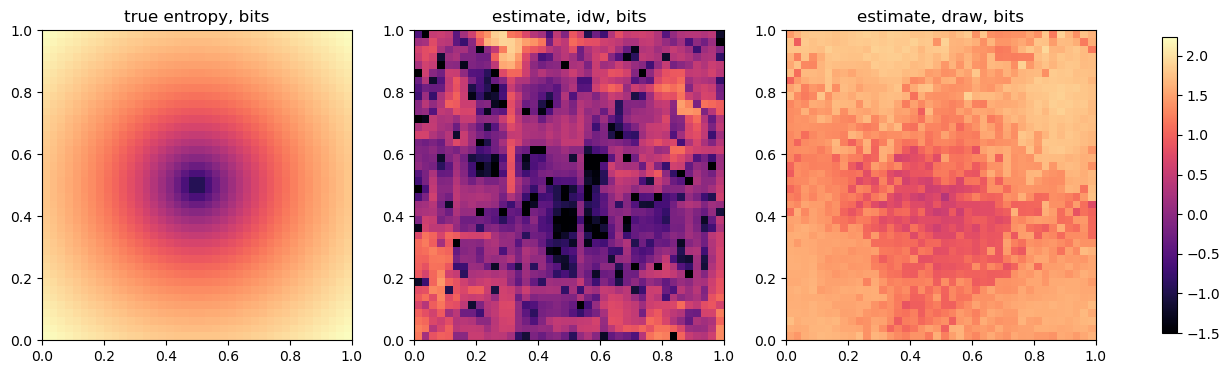

,rank correlation with the truth,"mean, bits","true mean, bits",seconds
idw,0.431,0.007,1.386,8.794
draw,0.622,1.390,1.386,8.404


In [2]:
entropies, seconds = {}, {}
for decoder, options in (("idw", dict(exponent=2.0)), ("draw", {})):
    start = time.perf_counter()
    estimator = SpatialEntropy(T=300, M=200, alpha_t=0.95, alpha_m=0.6, local_interpolator=decoder, callback=quiet, **options)
    entropies[decoder] = estimator.calculate_entropy(points, values, xi)
    seconds[decoder] = time.perf_counter() - start

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
lo, hi = true_entropy.min(), true_entropy.max()
for ax, (title, h) in zip(axes, [("true entropy", true_entropy)] + [(f"estimate, {d}", entropies[d]) for d in entropies]):
    im = ax.imshow(h.reshape(n, n).T, origin="lower", extent=(0, 1, 0, 1), cmap="magma", vmin=min(lo, -1.5), vmax=hi)
    ax.set_title(f"{title}, bits")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()
pd.DataFrame({d: {"rank correlation with the truth": spearmanr(h, true_entropy, nan_policy="omit")[0],
                  "mean, bits": np.nanmean(h), "true mean, bits": true_entropy.mean(), "seconds": seconds[d]}
              for d, h in entropies.items()}).T.round(3)

The two decoders tell different stories. The entropy of IDW's members averages 0.01 bits against a true
1.39, and its map shows the cells of the partitions as much as the field, since its members are cell
averages whose spread follows the granularity. The entropy of the uniform draw's members averages 1.39
bits, the true mean, and its map shows the low centre and the rising corners, with less contrast than
the truth, since each draw mixes the values of a whole cell. Its ranks follow the truth with a
correlation of 0.62.

### Two variables linked over half the region

$U$ follows a smooth pattern with some noise. $V$ follows the same pattern in the west, a mixture of it
and of independent noise in the middle, and independent noise alone in the east, so the true dependence
falls from full to none across the region. Each is read at its own 400 locations, as two networks of
sensors would be.

117 s


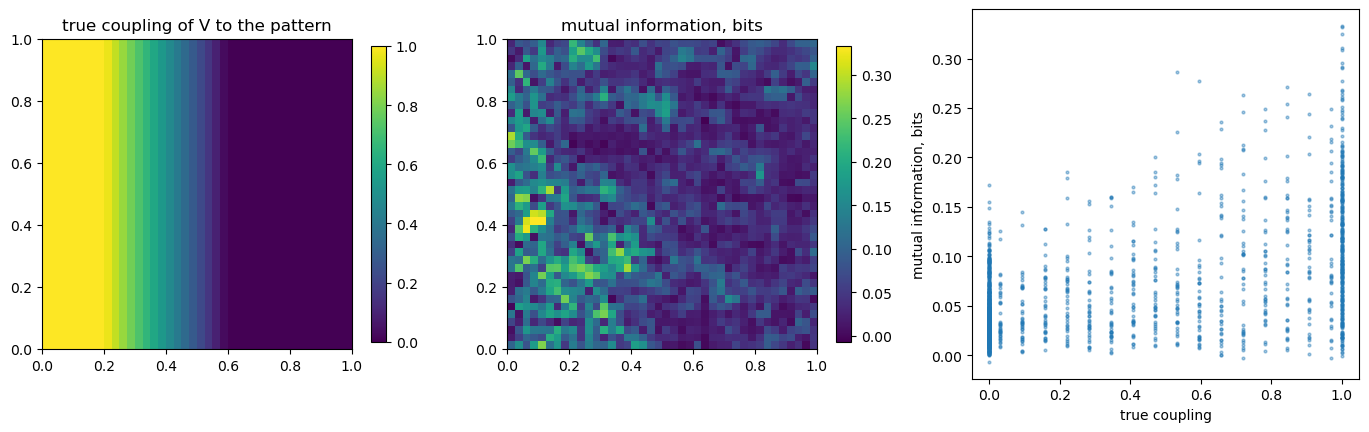

,0
rank correlation with the coupling,0.465
"mean in the west, bits",0.110
"mean in the east, bits",0.042


In [3]:
pattern = lambda x: np.sin(6 * x[:, 0]) + np.cos(5 * x[:, 1])
coupling = lambda x: np.clip(1.5 - 2.5 * x[:, 0], 0, 1)                 # 1 in the west, 0 in the east
points_u, points_v = rng.random((400, 2)), rng.random((400, 2))
values_u = pattern(points_u) + rng.normal(0, 0.3, 400)
w = coupling(points_v)
values_v = w * pattern(points_v) + (1 - w) * rng.normal(0, 1, 400) + rng.normal(0, 0.3, 400)

start = time.perf_counter()
smi = SpatialMutualInformation(T=300, M=200, alpha_t=0.8, alpha_m=0.9, exponent=2.0, callback=quiet)
mutual = smi.calculate_mutual_information(points_u, values_u, points_v, values_v, xi)
print(f"{time.perf_counter() - start:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
im = axes[0].imshow(coupling(xi).reshape(n, n).T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
axes[0].set_title("true coupling of V to the pattern"); fig.colorbar(im, ax=axes[0], shrink=0.8)
im = axes[1].imshow(mutual.reshape(n, n).T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
axes[1].set_title("mutual information, bits"); fig.colorbar(im, ax=axes[1], shrink=0.8)
axes[2].scatter(coupling(xi), mutual, s=4, alpha=0.4)
axes[2].set_xlabel("true coupling"); axes[2].set_ylabel("mutual information, bits")
plt.show()
west, east = xi[:, 0] < 0.3, xi[:, 0] > 0.7
pd.Series({"rank correlation with the coupling": spearmanr(mutual, coupling(xi), nan_policy="omit")[0],
           "mean in the west, bits": np.nanmean(mutual[west]), "mean in the east, bits": np.nanmean(mutual[east])}).round(3).to_frame()

The mutual information is higher where $V$ follows the pattern, 0.110 bits on average in the west
against 0.042 in the east, where $V$ is independent of $U$. Its ranks follow the true coupling with a
correlation of 0.47. The map is noisy from place to place, as an estimate from 300 members at each
location is, and the east keeps a small positive remainder after the correction. Read it as a map of
where the variables go together, not as a precise number at each place.

## Pitfalls

- **The entropy of an averaging decoder read as the field's.** Its members are cell averages, so their
  entropy says how much the estimate depends on the partition. Use a drawing decoder for the
  uncertainty of the value itself.
- **Entropies of different variables compared.** A differential entropy depends on the units, shifting by
  one bit when the variable doubles. Compare the entropy of one variable across places, not across
  variables.
- **Voronoi partitions with nuclei among the data for the mutual information.** The two variables are read
  at different places, so their nuclei differ and the ensembles share no partition. Use
  `data_cond=False`, whose nuclei are drawn at random in the region.
- **The mutual information without its correction.** A density from a few hundred members finds some
  dependence even between independent variables, the more so the finer `alpha_m`. Keep
  `bias_correction=True`, the default.
- **An experimental module.** Its interface and results may change between versions.

## Try it yourself

1. Map the entropy with `"wdraw_idw"`, the weighted draw, and compare it with the uniform draw.
2. Make $V$ depend on $U$ through its square, a dependence no correlation sees, and map the mutual
   information.
3. Change `alpha_m` from 0.9 to 0.7 and compare the contrast between west and east.

## Next

- *Uncertainty at a location*, for the law at a location and its widening.
- *The probabilistic decoders*, for the drawing decoders.
- The documentation's [Further readings](https://spatialize.readthedocs.io/en/latest/theory/other.html)
  (theory) and [Experimental features](https://spatialize.readthedocs.io/en/latest/reference/futures.html)
  (reference).